In [1]:
import pandas as pd
import numpy as np
from textblob import TextBlob
import plotly.express as px
import plotly.graph_objects as go
import warnings
warnings.filterwarnings('ignore')

# Chargement des données
df = pd.read_csv('../data/reviews_clean.csv')

print(f"Dataset chargé : {df.shape}")

# Analyse de sentiment avec TextBlob
def analyser_sentiment(texte):
    try:
        analyse = TextBlob(str(texte))
        polarite = analyse.sentiment.polarity
        if polarite > 0.1:
            return 'Positif', polarite
        elif polarite < -0.1:
            return 'Négatif', polarite
        else:
            return 'Neutre', polarite
    except:
        return 'Neutre', 0

# Appliquer l'analyse
df[['Sentiment_NLP', 'Polarite']] = df['Review'].apply(
    lambda x: pd.Series(analyser_sentiment(x))
)

print(f"\nRépartition sentiment NLP :")
print(df['Sentiment_NLP'].value_counts())

# Comparer avec les vrais labels
df['Sentiment_reel'] = df['Sentiment'].map({'Positive': 'Positif', 'Negative': 'Négatif'})
correct = (df['Sentiment_NLP'] == df['Sentiment_reel']).sum()
total = len(df[df['Sentiment_reel'] != 'Neutre'])
print(f"\nPrécision du modèle : {correct/len(df)*100:.1f}%")

Dataset chargé : (1502, 6)

Répartition sentiment NLP :
Sentiment_NLP
Positif    1289
Neutre      177
Négatif      36
Name: count, dtype: int64

Précision du modèle : 82.3%


In [2]:
# Visualisation 1 — Sentiment par pays
sentiment_pays = df.groupby(['Country', 'Sentiment_NLP']).size().reset_index(name='count')

fig1 = px.bar(
    sentiment_pays,
    x='Country',
    y='count',
    color='Sentiment_NLP',
    title='Analyse de sentiment par pays',
    color_discrete_map={
        'Positif': '#2ECC71',
        'Négatif': '#E74C3C',
        'Neutre': '#95A5A6'
    },
    barmode='group'
)
fig1.update_layout(
    yaxis_title="Nombre d'avis",
    xaxis_title="Pays",
    legend_title="Sentiment"
)
fig1.show()

# Visualisation 2 — Score de polarité par restaurant
polarite_resto = df.groupby('Restaurant Name')['Polarite'].mean().round(3).reset_index()
polarite_resto = polarite_resto.sort_values('Polarite', ascending=False)

fig2 = px.bar(
    polarite_resto,
    x='Restaurant Name',
    y='Polarite',
    title='Score de polarité moyen par restaurant',
    color='Polarite',
    color_continuous_scale='RdYlGn',
    text='Polarite'
)
fig2.update_traces(texttemplate='%{text:.3f}', textposition='outside')
fig2.update_layout(
    yaxis_title="Polarité moyenne (-1 à +1)",
    xaxis_title="Restaurant",
    xaxis_tickangle=-45,
    showlegend=False
)
fig2.show()

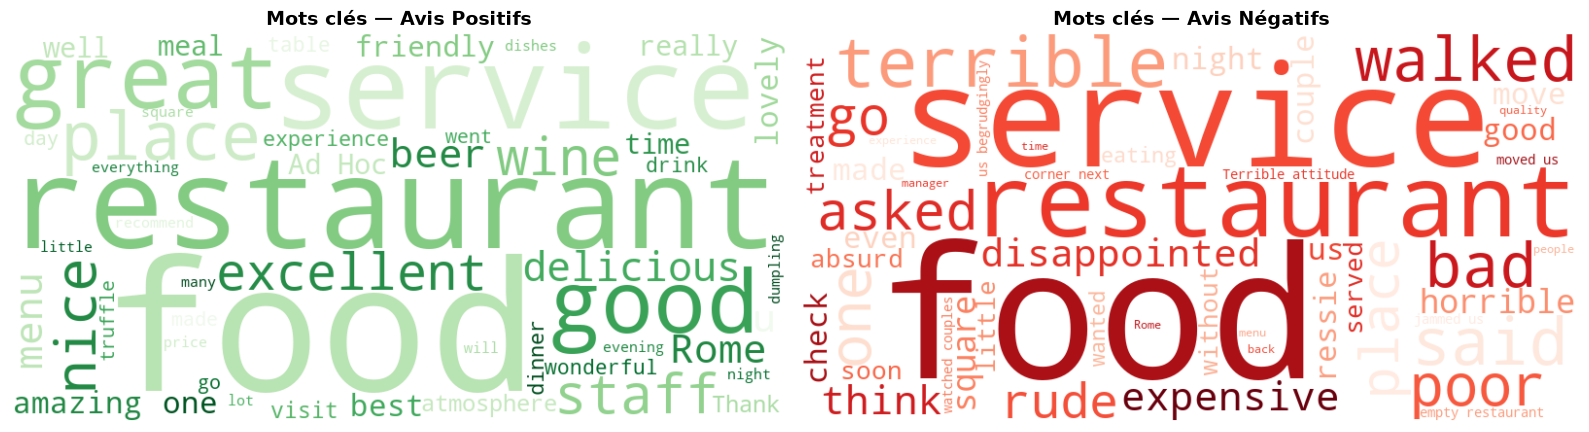

Nuage de mots sauvegardé !


In [3]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Nuage de mots — avis positifs
texte_positif = ' '.join(df[df['Sentiment_NLP'] == 'Positif']['Review'].astype(str))
texte_negatif = ' '.join(df[df['Sentiment_NLP'] == 'Négatif']['Review'].astype(str))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Positif
wc_positif = WordCloud(
    width=800, height=400,
    background_color='white',
    colormap='Greens',
    max_words=50
).generate(texte_positif)

axes[0].imshow(wc_positif, interpolation='bilinear')
axes[0].set_title('Mots clés — Avis Positifs', fontsize=14, fontweight='bold')
axes[0].axis('off')

# Négatif
wc_negatif = WordCloud(
    width=800, height=400,
    background_color='white',
    colormap='Reds',
    max_words=50
).generate(texte_negatif)

axes[1].imshow(wc_negatif, interpolation='bilinear')
axes[1].set_title('Mots clés — Avis Négatifs', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.savefig('../images/wordcloud_sentiment.png', dpi=150, bbox_inches='tight')
plt.show()
print("Nuage de mots sauvegardé !")

## Conclusions & insights business

### 🎯 Performance du modèle NLP
- **Précision : 82.3%** sur 1 502 avis réels Tripadvisor
- Modèle TextBlob sans entraînement spécifique

### 🏆 Classement restaurants par satisfaction
1. Mosaic (Inde) — 0.547
2. Stara Kamienica (Pologne) — 0.451
3. The LOFT (Maroc) — 0.425
4. Ad Hoc Ristorante (Italie) — 0.366
5. Pelmenya (Russie) — 0.322
6. The Frog at Bercy Village (France) — 0.322
7. Old Square (Cuba) — 0.286

### 💡 Insights clés
- **Le service** est le facteur le plus cité positivement ET négativement
- **La nourriture** est le deuxième facteur clé
- Les avis négatifs mentionnent souvent : rude, expensive, disappointed
- Les avis positifs mentionnent : excellent, delicious, friendly, wonderful

### 🎯 Application pour restaurants 
Cette méthodologie s'applique directement aux avis Google
de n'importe quel restaurant sur —
identifier automatiquement les points forts et faibles
à partir de centaines d'avis clients.